# SVM lề mềm và tham số C

*Bài 7, mục 7.1.2.* Khi dữ liệu không tách được tuyến tính (hoặc có nhiễu), cho phép một số điểm vi phạm lề bằng biến bù $\xi_i \ge 0$:
$$\min_{\mathbf{w}, b, \xi}\ \frac{1}{2}\|\mathbf{w}\|_2^2 + C\sum_{i=1}^N \xi_i \quad \text{với} \quad y_i(\mathbf{w}^T\mathbf{x}_i + b) \ge 1 - \xi_i,\ \xi_i \ge 0$$
Tương đương cực tiểu hóa $\frac{1}{2}\|\mathbf{w}\|^2 + C\sum_i \max(0, 1 - y_i(\mathbf{w}^T\mathbf{x}_i + b))$ (hàm mất mát **hinge**).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = make_blobs(n_samples=200, centers=[[0, 0], [2.5, 2.5]], cluster_std=1.0, random_state=1)
y = np.where(y == 0, -1, 1)                  # nhãn {-1, +1}
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

## 1. Ảnh hưởng của C
- $C$ nhỏ: phạt vi phạm nhẹ, ưu tiên lề rộng, nhiều vector hỗ trợ.
- $C$ lớn: phạt vi phạm nặng, lề hẹp, cố phân loại đúng mọi điểm huấn luyện (gần SVM lề cứng), dễ quá khớp.

In [2]:
for C in [0.01, 0.1, 1, 10, 100]:
    svm = SVC(kernel='linear', C=C).fit(X_train, y_train)
    w, b = svm.coef_[0], svm.intercept_[0]
    xi = np.maximum(0, 1 - y_train * (X_train @ w + b))     # biến bù xi_i
    print('C = %-6s độ rộng lề = %.3f, số vector hỗ trợ = %3d, số điểm vi phạm lề = %3d, '
          'huấn luyện %.3f, kiểm tra %.3f'
          % (C, 2 / np.linalg.norm(w), len(svm.support_), (xi > 1e-6).sum(),
             svm.score(X_train, y_train), svm.score(X_test, y_test)))

C = 0.01   độ rộng lề = 3.276, số vector hỗ trợ =  64, số điểm vi phạm lề =  62, huấn luyện 0.964, kiểm tra 0.933
C = 0.1    độ rộng lề = 1.861, số vector hỗ trợ =  27, số điểm vi phạm lề =  27, huấn luyện 0.964, kiểm tra 0.933
C = 1      độ rộng lề = 1.166, số vector hỗ trợ =  14, số điểm vi phạm lề =  12, huấn luyện 0.964, kiểm tra 0.933
C = 10     độ rộng lề = 1.058, số vector hỗ trợ =  12, số điểm vi phạm lề =  10, huấn luyện 0.964, kiểm tra 0.933
C = 100    độ rộng lề = 1.059, số vector hỗ trợ =  12, số điểm vi phạm lề =  10, huấn luyện 0.964, kiểm tra 0.933


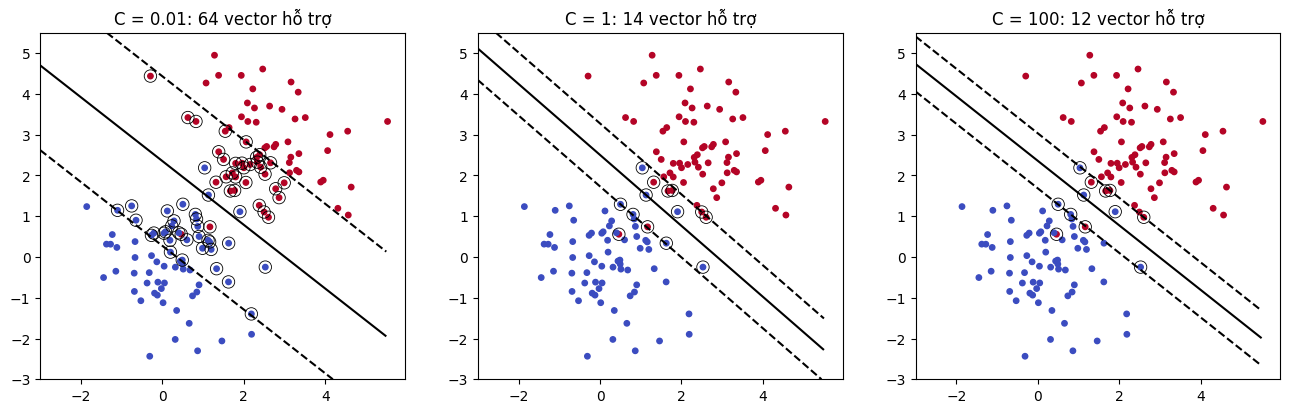

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
xx, yy = np.meshgrid(np.linspace(-3, 5.5, 300), np.linspace(-3, 5.5, 300))
for ax, C in zip(axes, [0.01, 1, 100]):
    svm = SVC(kernel='linear', C=C).fit(X_train, y_train)
    zz = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'])
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', s=15)
    ax.scatter(*svm.support_vectors_.T, s=80, facecolors='none', edgecolors='k', linewidths=0.6)
    ax.set_title('C = %s: %d vector hỗ trợ' % (C, len(svm.support_)))
plt.show()

Trên dữ liệu này hai lớp gần như tách được tuyến tính nên độ chính xác hầu như không đổi; C chủ yếu thay đổi độ rộng lề và số vector hỗ trợ. Với dữ liệu nhiễu hoặc dùng kernel phi tuyến (mục 7.1.3), C ảnh hưởng rõ tới quá khớp.

## 2. Chọn C bằng kiểm định chéo

In [4]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(SVC(kernel='linear'), {'C': [0.01, 0.1, 1, 10, 100]}, cv=5)
search.fit(X_train, y_train)
print('C tốt nhất:', search.best_params_['C'], ' độ chính xác kiểm định chéo: %.3f' % search.best_score_)
print('Độ chính xác kiểm tra: %.3f' % search.score(X_test, y_test))

C tốt nhất: 0.01  độ chính xác kiểm định chéo: 0.971
Độ chính xác kiểm tra: 0.933
